In [4]:
import numpy  as np

In [5]:
rng = np.random.default_rng(42)
X = rng.uniform(-2,2, size=(200, 1))
y = 3 * X[:,0] + 2 + rng.normal(0,0.5,size=200)

num_test =int(0.2 * len(X)) 

X_test = X[:num_test]
y_test = y[:num_test]

X_left = X[num_test:]
y_left = y[num_test:]

num_val = int(0.2 * len(X_left))

X_val = X_left[:num_val]
y_val = y_left[:num_val]

X_train = X_left[num_val:]
y_train = y_left[num_val:]

In [6]:
def predict(X,W,b):
    return X @ W + b

def me(y_pred,y):
    return y_pred - y

def loss(error):
    return 0.5 * np.mean(error ** 2)


def training_model(X,y,X_val=None,y_val=None,epochs=500,lr = 0.001):
    W = np.zeros(shape=X.shape[1])
    b = 0.0


    histories,vals = [],[]
    for _ in range(epochs):
        y_pred = predict(X,W,b)
        error = me(y_pred,y)
        grad_w = (X.T @ error)/len(X)
        grad_b = error.mean()

        W = W - lr * grad_w
        b = b - lr * grad_b
      
        histories.append(loss(error))
        if X_val is not None and y_val is not None:
            vals.append(loss(me(predict(X_val,W,b),y_val)))

    return histories,vals , W,b

In [7]:
y_train.shape

(128,)

In [8]:
import matplotlib.pyplot as plt

lr:0.001 | train_hist: 2.5785039407923662,val_hist : 1.9112401485841737
lr:0.01 | train_hist: 0.12251914180046468,val_hist : 0.16607012012064465
lr:0.1 | train_hist: 0.122350517343718,val_hist : 0.16790628266978558
best_lr : 0.01


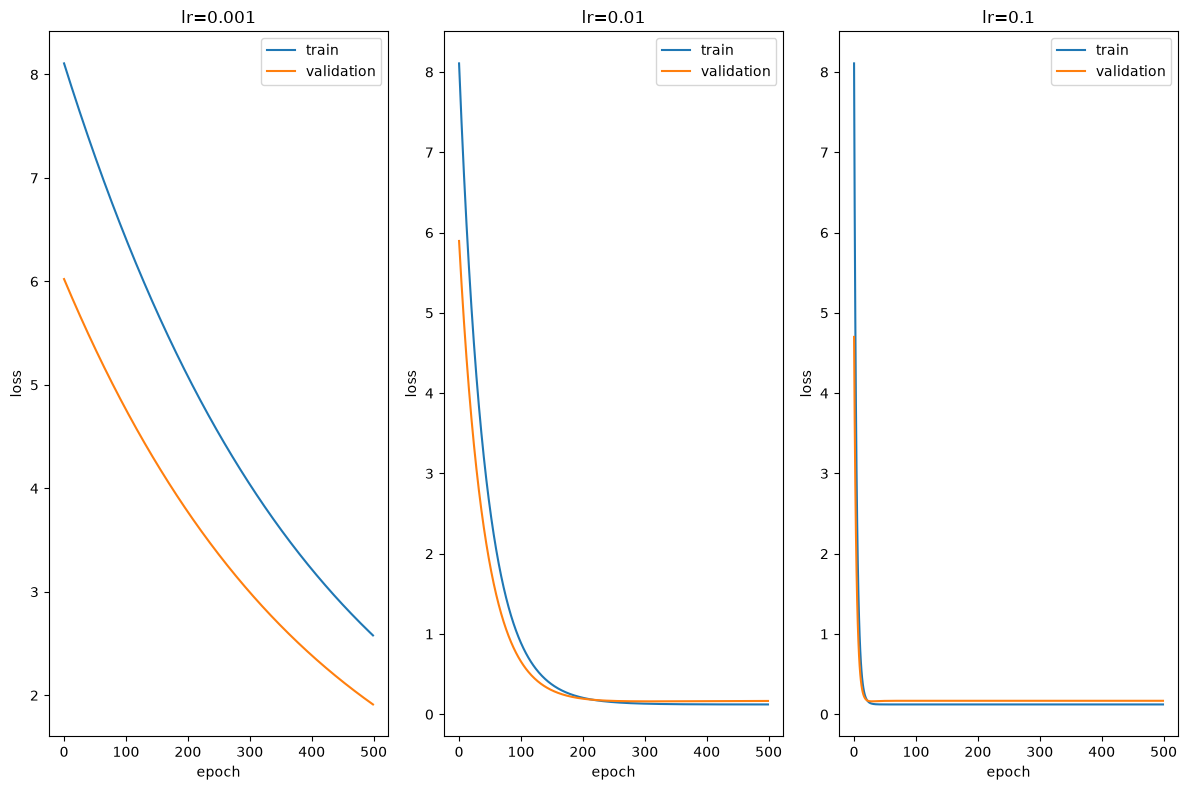

In [9]:
lrs = [0.001,0.01,0.1]
results = {}
for lr in lrs :
    hist,val, W,b = training_model(X_train,y_train,X_val,y_val,epochs=500,lr = lr)
    results[lr] = (W,b,hist,val)
    print(f"lr:{lr} | train_hist: {hist[-1]},val_hist : {val[-1]}")

best_lr = min(results, key=lambda k: results[k][3][-1])
print(f"best_lr : {best_lr}")


plt.figure(figsize=(12,8))
for i , (lr,(W,b,hist,val)) in enumerate(results.items(),1):
    plt.subplot(1,3,i)
    plt.plot(hist,label="train")
    plt.plot(val,label="validation")
    plt.title(f"lr={lr}")
    plt.xlabel("epoch")
    plt.ylabel("loss")
    plt.legend()
plt.tight_layout()

plt.show()

In [11]:
!python -m pip install scikit-learn

  Using cached scikit_learn-1.9.1-cp313-cp313-manylinux_2_27_x86_64.manylinux_2_28_x86_64.whl.metadata (9.3 kB)
  Using cached scipy-1.18.1-cp313-cp313-manylinux_2_27_x86_64.manylinux_2_28_x86_64.whl.metadata (62 kB)
  Using cached joblib-1.6.0-py3-none-any.whl.metadata (6.5 kB)
  Using cached narwhals-2.27.1-py3-none-any.whl.metadata (15 kB)
  Using cached threadpoolctl-3.7.0-py3-none-any.whl.metadata (24 kB)
  Using cached cloudpickle-3.1.2-py3-none-any.whl.metadata (7.1 kB)
Using cached scikit_learn-1.9.1-cp313-cp313-manylinux_2_27_x86_64.manylinux_2_28_x86_64.whl (9.1 MB)
Using cached joblib-1.6.0-py3-none-any.whl (306 kB)
Using cached cloudpickle-3.1.2-py3-none-any.whl (22 kB)
Using cached narwhals-2.27.1-py3-none-any.whl (483 kB)
Using cached scipy-1.18.1-cp313-cp313-manylinux_2_27_x86_64.manylinux_2_28_x86_64.whl (35.3 MB)
Using cached threadpoolctl-3.7.0-py3-none-any.whl (26 kB)
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 6/6 [scikit-learn] [scikit-learn]


In [12]:
from sklearn.linear_model import LinearRegression

In [14]:
sk = LinearRegression().fit(X_train,y_train)

print(sk.coef_)

[3.08283372]
